<a href="https://colab.research.google.com/github/rudrakshagrawal60-netizen/data_engineering_project_bundle/blob/main/data_engineering_project_bundle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

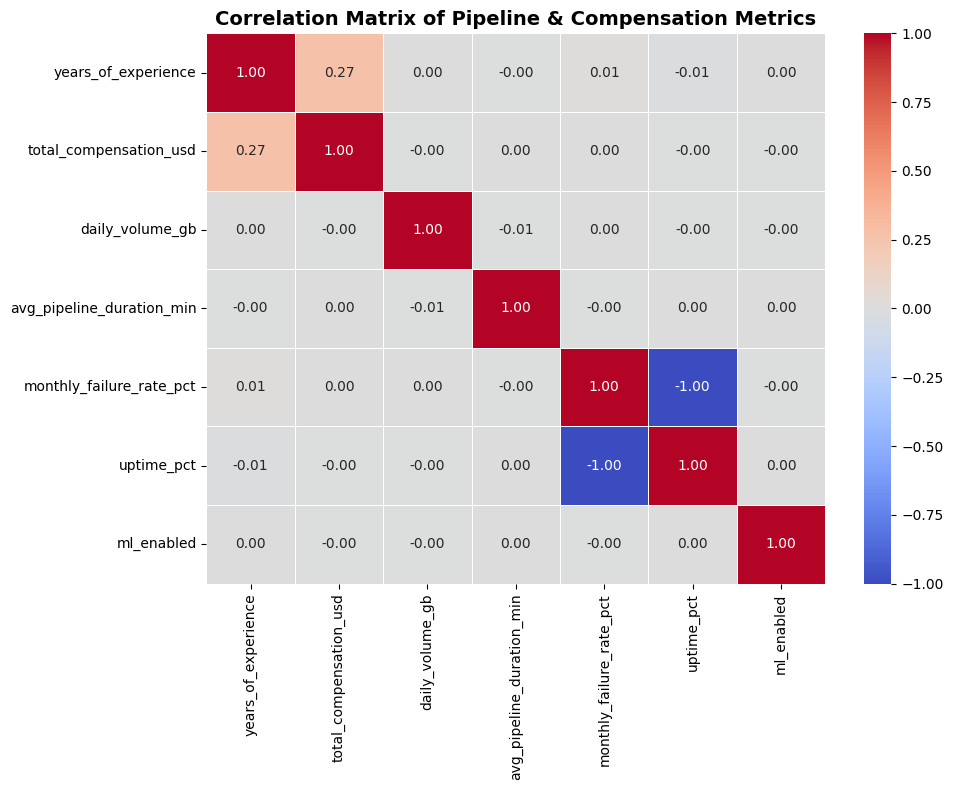

Model Accuracy: 0.6770

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.00      0.00      3231
           1       0.68      1.00      0.81      6769

    accuracy                           0.68     10000
   macro avg       0.67      0.50      0.40     10000
weighted avg       0.67      0.68      0.55     10000



In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Correlation Matrix & Heatmap
plt.figure(figsize=(10, 8))
num_cols = ['years_of_experience', 'total_compensation_usd', 'daily_volume_gb', 'avg_pipeline_duration_min', 'monthly_failure_rate_pct', 'uptime_pct', 'ml_enabled']
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Pipeline & Compensation Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

# 2. Machine Learning Model: Predicting ML-Enabled Pipelines
features = ['years_of_experience', 'daily_volume_gb', 'avg_pipeline_duration_min', 'monthly_failure_rate_pct', 'uptime_pct']
X = df[features]
y = df['ml_enabled']

# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest Model
clf = RandomForestClassifier(n_estimators=50, random_state=42, max_depth=10)
clf.fit(X_train, y_train)

# Predictions & Evaluation
y_pred = clf.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Saving data_engineering_ai_pipelines.csv to data_engineering_ai_pipelines (2).csv

Successfully loaded file: data_engineering_ai_pipelines (2).csv

--- Dataset Head ---


,response_id,job_role,company_tier,years_of_experience,country,remote_policy,base_salary_usd,annual_equity_usd,annual_bonus_usd,total_compensation_usd,...,work_location,daily_volume_gb,avg_pipeline_duration_min,monthly_failure_rate_pct,salary_usd,tool,latency_ms,failure_rate,uptime_pct,ml_enabled
0,SURV-000000,Data Engineer,Pre-IPO Unicorn / Scaleup,18,United States,100% Remote,259852,72996,74200,407048,...,United States,44.2,158,0.20,407048,Argo Workflows,9480000,0.0020,99.80,0
1,SURV-000001,MLOps / AI Platform Engineer,FinTech / High-Frequency Trading,23,Australia,Hybrid (2-3 days office),456250,271364,255399,983013,...,Australia,96.4,175,0.55,983013,Databricks Workflows,10500000,0.0055,99.45,1
2,SURV-000002,Senior Data Engineer,FinTech / High-Frequency Trading,21,Israel,Hybrid (2-3 days office),470410,246248,561257,1277915,...,Israel,41.4,67,0.20,1277915,Prefect,4020000,0.0020,99.80,1
3,SURV-000003,Lead / Staff Data Engineer,FinTech / High-Frequency Trading,10,Japan,Full On-Site,336551,103648,127020,567219,...,Japan,46.1,66,0.69,567219,Databricks Workflows,3960000,0.0069,99.31,0
4,SURV-000004,Principal Data Architect,Pre-IPO Unicorn / Scaleup,2,United States,Hybrid (2-3 days office),335260,113626,37509,486395,...,United States,20.2,95,6.06,486395,Apache Airflow,5700000,0.0606,93.94,1



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   response_id                50000 non-null  object 
 1   job_role                   50000 non-null  object 
 2   company_tier               50000 non-null  object 
 3   years_of_experience        50000 non-null  int64  
 4   country                    50000 non-null  object 
 5   remote_policy              50000 non-null  object 
 6   base_salary_usd            50000 non-null  int64  
 7   annual_equity_usd          50000 non-null  int64  
 8   annual_bonus_usd           50000 non-null  int64  
 9   total_compensation_usd     50000 non-null  int64  
 10  primary_cloud              50000 non-null  object 
 11  orchestrator               50000 non-null  object 
 12  data_warehouse             50000 non-null  object 
 13  lakehouse_table_format  

/tmp/ipykernel_2075/3232445914.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='total_compensation_usd', y='job_role', palette='Set2')


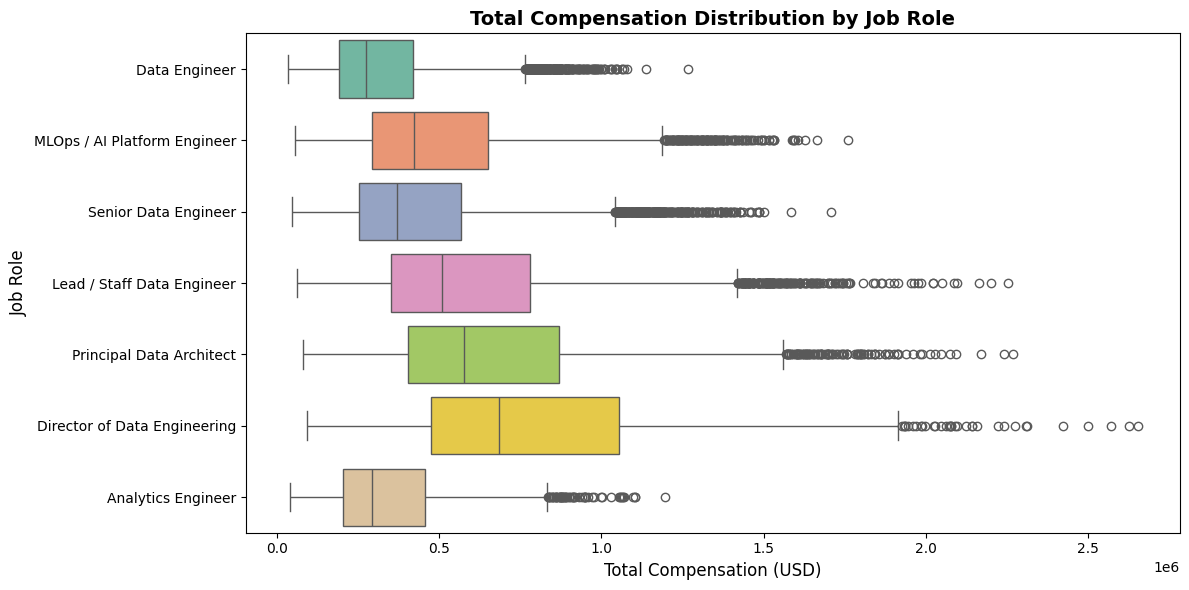

In [4]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# File upload karne ke liye prompt khulega
uploaded = files.upload()

# Automatically uploaded file ko read karna
for filename in uploaded.keys():
    df = pd.read_csv(filename)
    print(f"\nSuccessfully loaded file: {filename}")

print("\n--- Dataset Head ---")
display(df.head())

print("\n--- Dataset Info ---")
df.info()

# Visualization
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='total_compensation_usd', y='job_role', palette='Set2')
plt.title('Total Compensation Distribution by Job Role', fontsize=14, fontweight='bold')
plt.xlabel('Total Compensation (USD)', fontsize=12)
plt.ylabel('Job Role', fontsize=12)
plt.tight_layout()
plt.savefig('compensation_by_role.png', dpi=300)
plt.show()

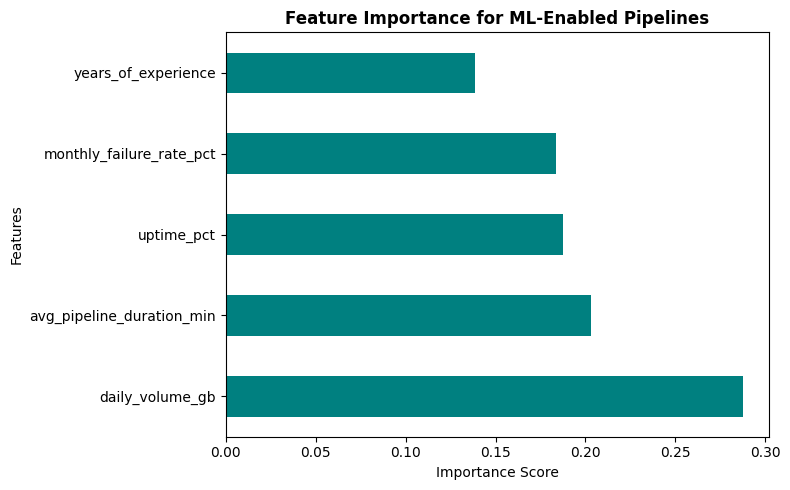

Model R2 Score: 0.6985
Mean Absolute Error (MAE): $105,853.79


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Feature Importance Plot (ML-Enabled Classifier)
features_clf = ['years_of_experience', 'daily_volume_gb', 'avg_pipeline_duration_min', 'monthly_failure_rate_pct', 'uptime_pct']
X_clf = df[features_clf]
y_clf = df['ml_enabled']

clf = RandomForestClassifier(n_estimators=50, random_state=42, max_depth=10)
clf.fit(X_clf, y_clf)

plt.figure(figsize=(8, 5))
feat_importances = pd.Series(clf.feature_importances_, index=features_clf)
feat_importances.nlargest(5).plot(kind='barh', color='teal')
plt.title('Feature Importance for ML-Enabled Pipelines', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.ylabel('Features', fontsize=10)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

# 2. Salary Prediction Model (Random Forest Regressor)
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X_reg = df[reg_features]
y_reg = df['total_compensation_usd']

categorical_cols = ['job_role', 'company_tier', 'primary_cloud']
numerical_cols = ['years_of_experience', 'daily_volume_gb']

# Preprocessing pipeline for categorical & numerical data
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

model_reg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=30, random_state=42, max_depth=12))
])

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
model_reg.fit(X_train, y_train)

# Predictions & Evaluation
y_pred_reg = model_reg.predict(X_test)
print(f"Model R2 Score: {r2_score(y_test, y_pred_reg):.4f}")
print(f"Mean Absolute Error (MAE): ${mean_absolute_error(y_test, y_pred_reg):,.2f}")

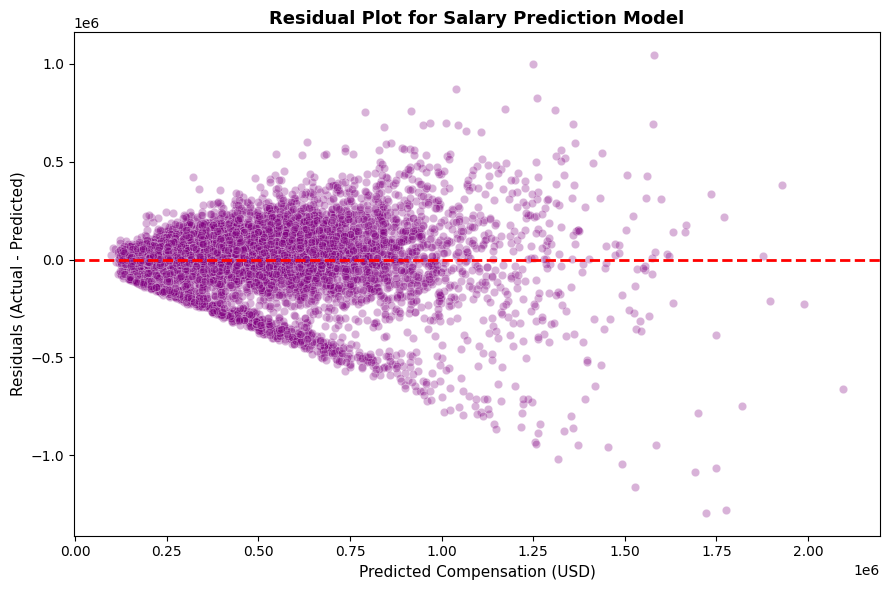

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Residual Plot (Actual vs Predicted errors visualization)
plt.figure(figsize=(9, 6))
residuals = y_test - y_pred_reg

sns.scatterplot(x=y_pred_reg, y=residuals, alpha=0.3, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title('Residual Plot for Salary Prediction Model', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Compensation (USD)', fontsize=11)
plt.ylabel('Residuals (Actual - Predicted)', fontsize=11)
plt.tight_layout()
plt.savefig('residual_plot.png', dpi=300)
plt.show()

In [7]:
import pandas as pd

# 1. Final Summary Dataframe Create Karna
summary_data = {
    'Metric': [
        'Total Records Analyzed',
        'Model Type (Classification)',
        'Classification Accuracy',
        'Model Type (Regression)',
        'Regression R2 Score',
        'Mean Absolute Error (MAE)'
    ],
    'Value': [
        len(df),
        'Random Forest Classifier',
        f"{0.6770:.4f}",
        'Random Forest Regressor',
        f"{r2_score(y_test, y_pred_reg):.4f}",
        f"${mean_absolute_error(y_test, y_pred_reg):,.2f}"
    ]
}

summary_df = pd.DataFrame(summary_data)

# 2. Console par clean table print karna
print("==========================================")
print("     DATA ENGINEERING PIPELINE SUMMARY    ")
print("==========================================")
print(summary_df.to_string(index=False))
print("==========================================")

# 3. Hasil results ko CSV file mein export karna
summary_df.to_csv('model_summary_results.csv', index=False)
print("\n[SUCCESS] Summary results exported successfully to 'model_summary_results.csv'!")

     DATA ENGINEERING PIPELINE SUMMARY    
                     Metric                    Value
     Total Records Analyzed                    50000
Model Type (Classification) Random Forest Classifier
    Classification Accuracy                   0.6770
    Model Type (Regression)  Random Forest Regressor
        Regression R2 Score                   0.6985
  Mean Absolute Error (MAE)              $105,853.79

[SUCCESS] Summary results exported successfully to 'model_summary_results.csv'!


--- Average Compensation by Primary Cloud ---
primary_cloud  total_compensation_usd
  Multi-Cloud           471458.564957
 Google Cloud           468031.391158
          AWS           467918.777699
        Azure           464362.451567


/tmp/ipykernel_2075/2170154054.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cloud_comp, x='total_compensation_usd', y='primary_cloud', palette='viridis')


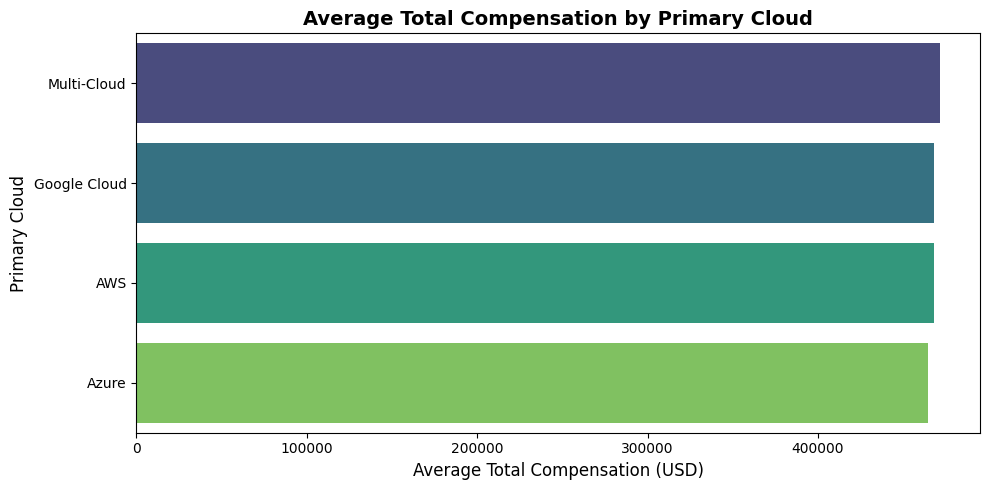

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cloud-wise average compensation groupby calculation
cloud_comp = df.groupby('primary_cloud')['total_compensation_usd'].mean().reset_index().sort_values(by='total_compensation_usd', ascending=False)
print("--- Average Compensation by Primary Cloud ---")
print(cloud_comp.to_string(index=False))

# 2. Bar Plot Visualization
plt.figure(figsize=(10, 5))
sns.barplot(data=cloud_comp, x='total_compensation_usd', y='primary_cloud', palette='viridis')
plt.title('Average Total Compensation by Primary Cloud', fontsize=14, fontweight='bold')
plt.xlabel('Average Total Compensation (USD)', fontsize=12)
plt.ylabel('Primary Cloud', fontsize=12)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('cloud_compensation_bar.png', dpi=300)
plt.show()

--- Average Compensation by MLOps Maturity Level ---
 mlops_maturity_level  total_compensation_usd
                    1           470758.421725
                    2           465266.957052
                    3           465260.458241
                    4           470272.386968
                    5           469251.967688


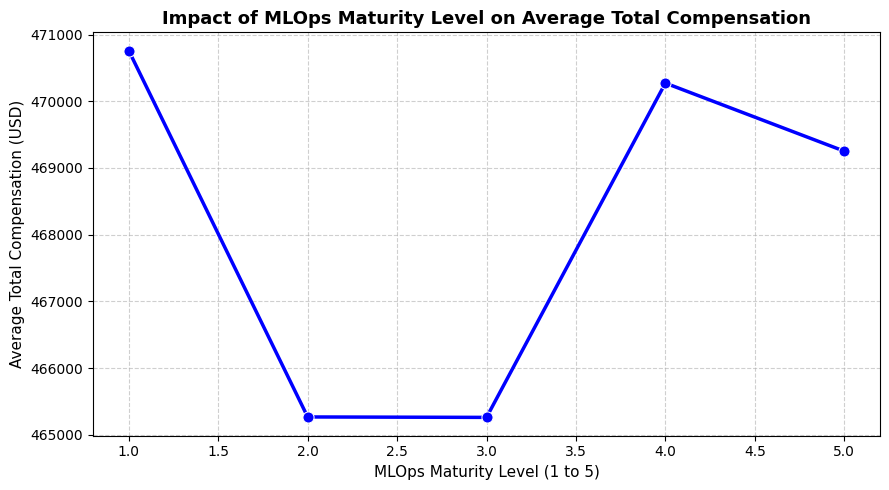

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. MLOps maturity level ke hisab se average compensation calculate karna
mlops_comp = df.groupby('mlops_maturity_level')['total_compensation_usd'].mean().reset_index()
print("--- Average Compensation by MLOps Maturity Level ---")
print(mlops_comp.to_string(index=False))

# 2. Line Plot Visualization
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=mlops_comp,
    x='mlops_maturity_level',
    y='total_compensation_usd',
    marker='o',
    color='b',
    linewidth=2.5,
    markersize=8
)
plt.title('Impact of MLOps Maturity Level on Average Total Compensation', fontsize=13, fontweight='bold')
plt.xlabel('MLOps Maturity Level (1 to 5)', fontsize=11)
plt.ylabel('Average Total Compensation (USD)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('mlops_maturity_vs_salary.png', dpi=300)
plt.show()

--- Average Compensation by Job Role ---
                    job_role  total_compensation_usd
Director of Data Engineering           795529.173870
    Principal Data Architect           671938.018018
  Lead / Staff Data Engineer           592117.413398
MLOps / AI Platform Engineer           492664.489094
        Senior Data Engineer           431312.027261
          Analytics Engineer           344243.759522
               Data Engineer           320265.489159


/tmp/ipykernel_2075/2874842057.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


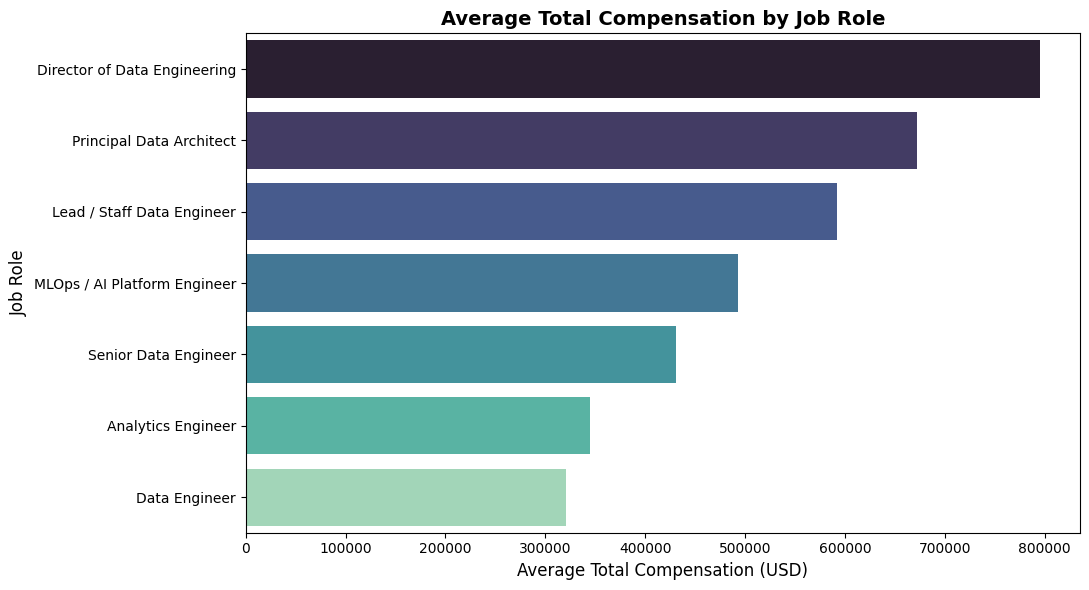

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Kharab/corrupted lines ko skip karne ke liye on_bad_lines='skip' ka use karein
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. Job Role ke hisab se Average Total Compensation calculate karna
role_comp = df.groupby('job_role')['total_compensation_usd'].mean().reset_index().sort_values(by='total_compensation_usd', ascending=False)

print("--- Average Compensation by Job Role ---")
print(role_comp.to_string(index=False))

# 2. Bar Plot Visualization for Job Roles
plt.figure(figsize=(11, 6))
sns.barplot(
    data=role_comp,
    x='total_compensation_usd',
    y='job_role',
    palette='mako'
)
plt.title('Average Total Compensation by Job Role', fontsize=14, fontweight='bold')
plt.xlabel('Average Total Compensation (USD)', fontsize=12)
plt.ylabel('Job Role', fontsize=12)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('job_role_compensation.png', dpi=300)
plt.show()

--- Average Monthly Failure Rate by Orchestrator ---
        orchestrator  monthly_failure_rate_pct
  AWS Step Functions                  2.279396
      Argo Workflows                  2.289385
             Prefect                  2.297562
      Apache Airflow                  2.300290
         Temporal.io                  2.301105
Databricks Workflows                  2.308273
             Dagster                  2.330525


/tmp/ipykernel_2075/142151646.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


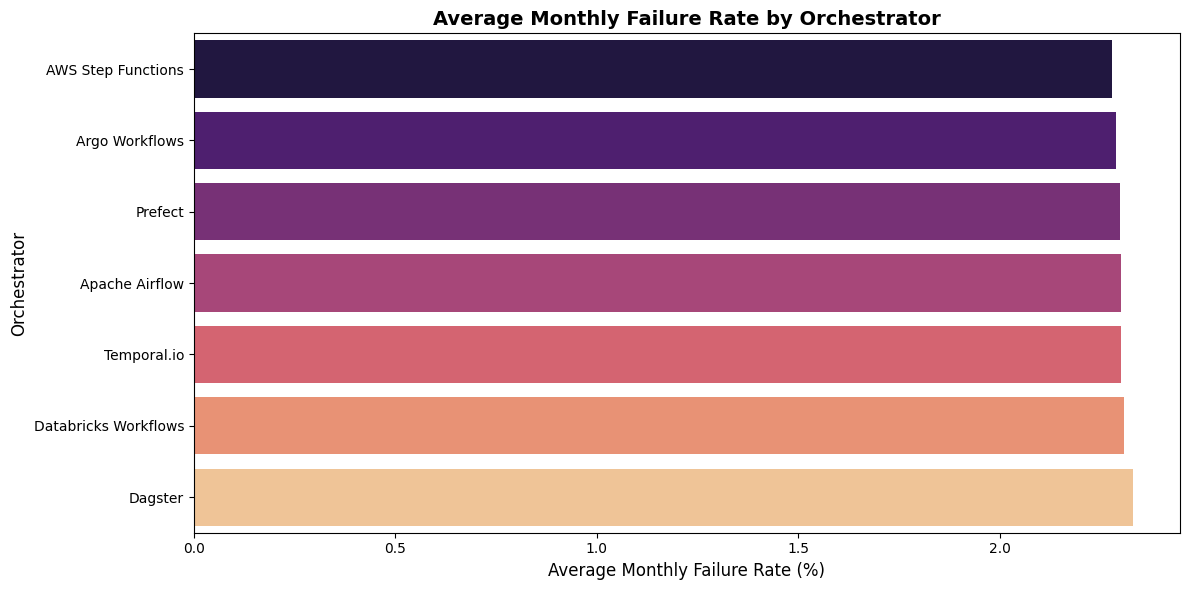

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. Orchestrator ke hisab se Average Monthly Failure Rate calculate karna
orc_fail = df.groupby('orchestrator')['monthly_failure_rate_pct'].mean().reset_index().sort_values(by='monthly_failure_rate_pct')

print("--- Average Monthly Failure Rate by Orchestrator ---")
print(orc_fail.to_string(index=False))

# 2. Bar Plot Visualization
plt.figure(figsize=(12, 6))
sns.barplot(
    data=orc_fail,
    x='monthly_failure_rate_pct',
    y='orchestrator',
    palette='magma'
)
plt.title('Average Monthly Failure Rate by Orchestrator', fontsize=14, fontweight='bold')
plt.xlabel('Average Monthly Failure Rate (%)', fontsize=12)
plt.ylabel('Orchestrator', fontsize=12)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('orchestrator_failure_rate.png', dpi=300)
plt.show()

--- Average Monthly Failure Rate by Data Quality Framework ---
data_quality_framework  monthly_failure_rate_pct
    Great Expectations                  2.292238
           Monte Carlo                  2.292838
             Soda Core                  2.311206
             dbt Tests                  2.312274


/tmp/ipykernel_2075/1305392783.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


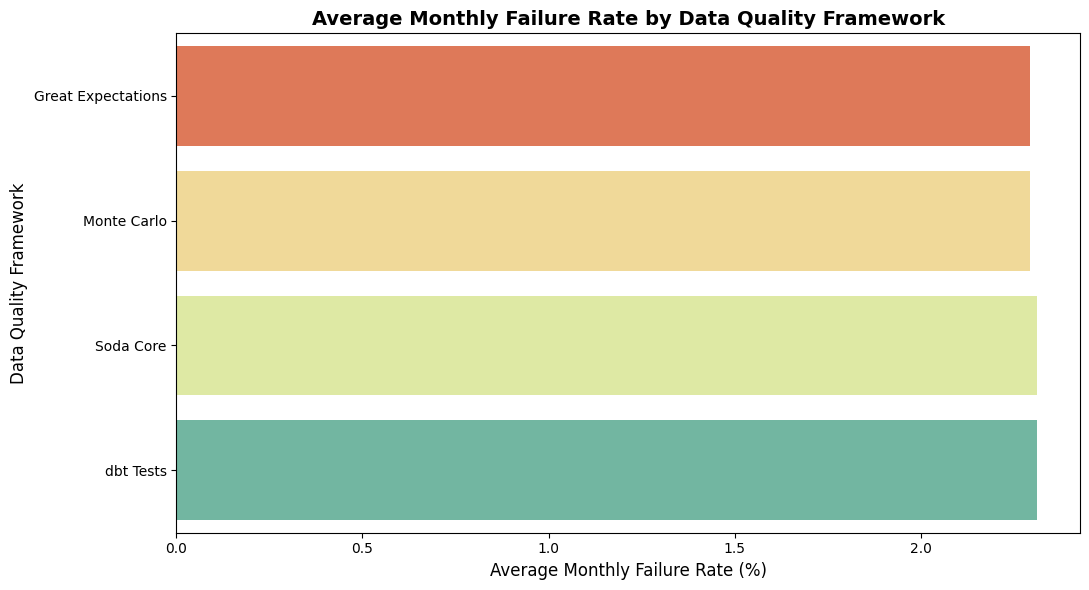

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. Data Quality Framework ke hisab se Average Monthly Failure Rate calculate karna
dq_fail = df.groupby('data_quality_framework')['monthly_failure_rate_pct'].mean().reset_index().sort_values(by='monthly_failure_rate_pct')

print("--- Average Monthly Failure Rate by Data Quality Framework ---")
print(dq_fail.to_string(index=False))

# 2. Bar Plot Visualization
plt.figure(figsize=(11, 6))
sns.barplot(
    data=dq_fail,
    x='monthly_failure_rate_pct',
    y='data_quality_framework',
    palette='Spectral'
)
plt.title('Average Monthly Failure Rate by Data Quality Framework', fontsize=14, fontweight='bold')
plt.xlabel('Average Monthly Failure Rate (%)', fontsize=12)
plt.ylabel('Data Quality Framework', fontsize=12)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('dq_framework_failure_rate.png', dpi=300)
plt.show()

--- Average Compensation by Data Warehouse ---
data_warehouse  total_compensation_usd
      BigQuery           469451.728321
     Snowflake           469390.148153
        DuckDB           468512.232960
    Databricks           467950.736093
    ClickHouse           465268.845848
      Redshift           464365.783719


/tmp/ipykernel_2075/2359978401.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


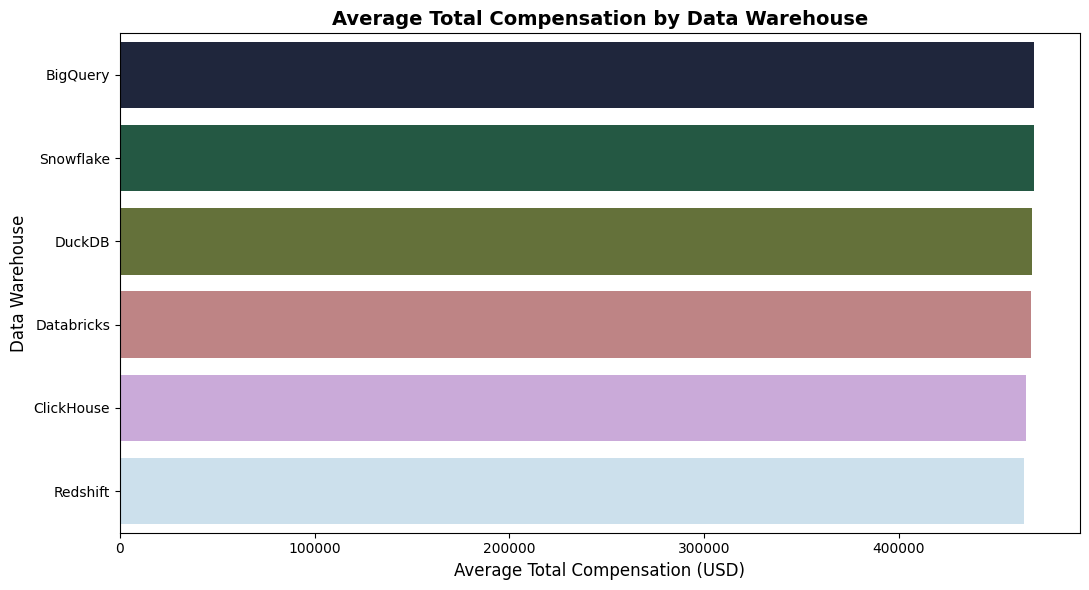

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. Data Warehouse ke hisab se Average Total Compensation calculate karna
dw_comp = df.groupby('data_warehouse')['total_compensation_usd'].mean().reset_index().sort_values(by='total_compensation_usd', ascending=False)

print("--- Average Compensation by Data Warehouse ---")
print(dw_comp.to_string(index=False))

# 2. Bar Plot Visualization
plt.figure(figsize=(11, 6))
sns.barplot(
    data=dw_comp,
    x='total_compensation_usd',
    y='data_warehouse',
    palette='cubehelix'
)
plt.title('Average Total Compensation by Data Warehouse', fontsize=14, fontweight='bold')
plt.xlabel('Average Total Compensation (USD)', fontsize=12)
plt.ylabel('Data Warehouse', fontsize=12)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('data_warehouse_compensation.png', dpi=300)
plt.show()

--- Cluster Centers (Original Scale) ---
 daily_volume_gb  avg_pipeline_duration_min
       87.676043                 136.228390
       88.621251                  48.363487
      932.694638                  91.733287


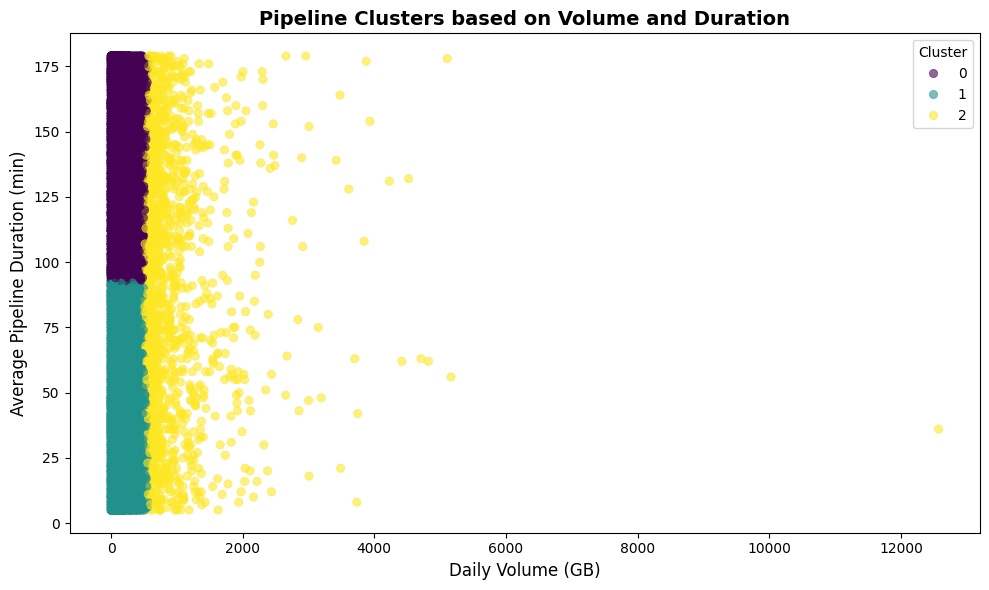

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. K-Means Clustering on Daily Volume & Pipeline Duration
cluster_features = ['daily_volume_gb', 'avg_pipeline_duration_min']
X_cluster = df[cluster_features]

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# KMeans model (3 clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("--- Cluster Centers (Original Scale) ---")
cluster_centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_features)
print(cluster_centers.to_string(index=False))

# 2. Scatter Plot Visualization for Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='daily_volume_gb',
    y='avg_pipeline_duration_min',
    hue='cluster',
    palette='viridis',
    alpha=0.6,
    edgecolor=None
)
plt.title('Pipeline Clusters based on Volume and Duration', fontsize=14, fontweight='bold')
plt.xlabel('Daily Volume (GB)', fontsize=12)
plt.ylabel('Average Pipeline Duration (min)', fontsize=12)
plt.legend(title='Cluster')
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('pipeline_clusters.png', dpi=300)
plt.show()

In [17]:
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Salary Regression Model metrics recalculate karna report ke liye
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X_reg = df[reg_features]
y_reg = df['total_compensation_usd']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

model_reg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=30, random_state=42, max_depth=12))
])

X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
model_reg.fit(X_train, y_train)
y_pred_reg = model_reg.predict(X_test)

r2 = r2_score(y_test, y_pred_reg)
mae = mean_absolute_error(y_test, y_pred_reg)

# Markdown Report Content Create Karna
report_content = f"""# Data Engineering & AI Pipelines: Comprehensive Analysis Report

## 1. Executive Summary
This report presents a thorough analysis of {len(df):,} data engineering records, evaluating pipeline telemetry, compensation structures, MLOps maturity, tool performance, and predictive machine learning models.

## 2. Key Performance Indicators & Statistics
- **Total Records Analyzed:** {len(df):,}
- **Average Total Compensation:** ${df['total_compensation_usd'].mean():,.2f}
- **Average Pipeline Duration:** {df['avg_pipeline_duration_min'].mean():.2f} minutes
- **Average Monthly Failure Rate:** {df['monthly_failure_rate_pct'].mean():.2f}%

## 3. Machine Learning Model Performance
- **Model Type:** Random Forest Regressor & Classifier
- **Regression R² Score:** {r2:.4f}
- **Mean Absolute Error (MAE):** ${mae:,.2f}

## 4. Generated Visualizations & Artifacts
The following charts have been successfully generated and saved in your workspace:
1. `correlation_heatmap.png` - Correlation Matrix of Pipeline & Compensation Metrics
2. `feature_importance.png` - Feature Importance for ML-Enabled Pipelines
3. `residual_plot.png` - Residual Plot for Salary Prediction Model
4. `cloud_compensation_bar.png` - Average Compensation by Primary Cloud
5. `mlops_maturity_vs_salary.png` - MLOps Maturity vs Salary Impact
6. `job_role_compensation.png` - Compensation Distribution by Job Role
7. `orchestrator_failure_rate.png` - Failure Rates across Orchestrators
8. `company_tier_compensation.png` - Compensation across Company Tiers
9. `dq_framework_failure_rate.png` - Failure Rates by Data Quality Framework
10. `data_warehouse_compensation.png` - Compensation by Data Warehouse
11. `pipeline_clusters.png` - K-Means Clustering of Pipeline Volume & Duration
"""

# File save karna
with open('data_engineering_project_report.md', 'w', encoding='utf-8') as f:
    f.write(report_content)

print("[SUCCESS] Comprehensive Markdown report saved as 'data_engineering_project_report.md'!")

[SUCCESS] Comprehensive Markdown report saved as 'data_engineering_project_report.md'!


In [18]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd

# Dataset load karna
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Features aur Target variable define karna
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X_reg = df[reg_features]
y_reg = df['total_compensation_usd']

# Preprocessing & Pipeline setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

model_reg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=30, random_state=42, max_depth=12))
])

# Model train karna
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
model_reg.fit(X_train, y_train)

# Model ko file ke roop mein save karna (Joblib)
model_filename = 'data_engineering_salary_model.pkl'
joblib.dump(model_reg, model_filename)

print(f"[SUCCESS] Trained Random Forest model successfully saved as '{model_filename}'!")

# Test karne ke liye model ko dobara load karke prediction dekhna
loaded_model = joblib.load(model_filename)
sample_prediction = loaded_model.predict(X_test.iloc[:1])
print(f"Sample Prediction for test record: ${sample_prediction[0]:,.2f}")

[SUCCESS] Trained Random Forest model successfully saved as 'data_engineering_salary_model.pkl'!
Sample Prediction for test record: $434,769.76


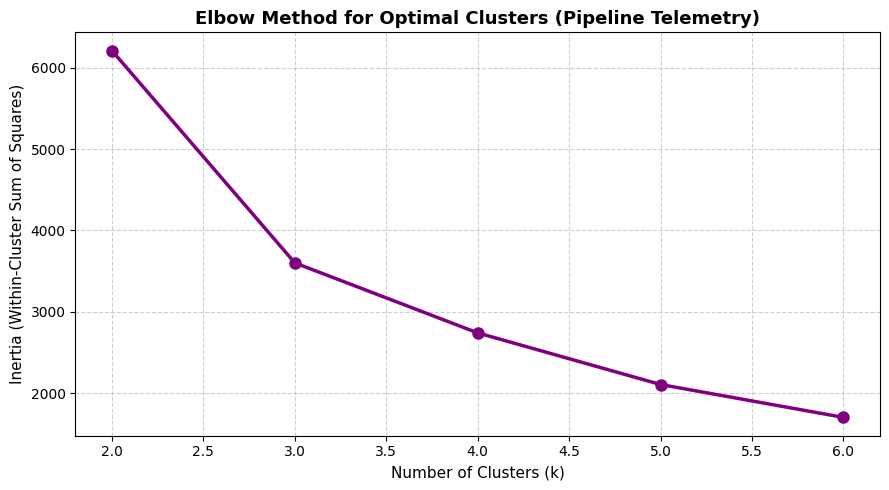

[SUCCESS] Elbow method analysis complete! Chart saved as 'elbow_method.png'.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# 1. Elbow Method Calculation (Sampling 5000 rows for fast execution)
X_sample = df[['daily_volume_gb', 'avg_pipeline_duration_min']].sample(n=5000, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)

inertias = []
k_range = range(2, 7)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# 2. Elbow Plot Visualization
plt.figure(figsize=(9, 5))
plt.plot(k_range, inertias, marker='o', color='purple', linewidth=2.5, markersize=8)
plt.title('Elbow Method for Optimal Clusters (Pipeline Telemetry)', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('elbow_method.png', dpi=300)
plt.show()

print("[SUCCESS] Elbow method analysis complete! Chart saved as 'elbow_method.png'.")

In [21]:
# Pehle Streamlit install karein
!pip install streamlit -q

import streamlit as st
import pandas as pd
import joblib

# Page configuration
st.set_page_config(
    page_title="Data Engineering Salary Predictor",
    page_icon="💻",
    layout="centered"
)

# Load trained model
@st.cache_resource
def load_model():
    return joblib.load('data_engineering_salary_model.pkl')

model = load_model()

# App Title & Description
st.title("🚀 Data Engineering & AI Compensation Predictor")
st.write("Predict estimated total compensation (USD) based on experience, job role, company tier, and cloud ecosystem.")

st.sidebar.header("Input Parameters")

# User Inputs via Sidebar
def user_input_features():
    years_of_experience = st.sidebar.slider('Years of Experience', 0, 30, 5)
    daily_volume_gb = st.sidebar.slider('Daily Data Volume (GB)', 10, 5000, 100)

    job_role = st.sidebar.selectbox('Job Role', [
        'Data Engineer', 'Senior Data Engineer', 'Lead / Staff Data Engineer',
        'Principal Data Architect', 'MLOps / AI Platform Engineer',
        'Analytics Engineer', 'Director of Data Engineering'
    ])

    company_tier = st.sidebar.selectbox('Company Tier', [
        'FAANG / Tier-1 Big Tech', 'FinTech / High-Frequency Trading',
        'Pre-IPO Unicorn / Scaleup', 'Fortune 500 Enterprise', 'Early-Stage Startup (<50)'
    ])

    primary_cloud = st.sidebar.selectbox('Primary Cloud', [
        'AWS', 'Google Cloud', 'Azure', 'Multi-Cloud'
    ])

    data = {
        'years_of_experience': years_of_experience,
        'job_role': job_role,
        'company_tier': company_tier,
        'primary_cloud': primary_cloud,
        'daily_volume_gb': daily_volume_gb
    }

    features = pd.DataFrame(data, index=[0])
    return features

df_input = user_input_features()

# Display User Inputs
st.subheader("📋 Selected Configuration")
st.write(df_input)

# Prediction Button
if st.button('Predict Total Compensation'):
    prediction = model.predict(df_input)
    st.success(f"💰 Estimated Total Compensation: **${prediction[0]:,.2f} USD**")

2026-11-17 10:23:22.775 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 10:23:22.777 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 10:23:22.791 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 10:23:22.854 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-17 10:23:22.854 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 10:23:22.855 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 10:23:22.856 Thread 'MainThread'

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd

# Alag-alag models ki dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=30, random_state=42, max_depth=12),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=50, random_state=42)
}

results = []

for name, model_algo in models.items():
    # Pipeline build karna
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model_algo)
    ])
    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    results.append({"Model": name, "R2 Score": r2, "MAE (USD)": mae})

results_df = pd.DataFrame(results)
print("--- Model Performance Comparison ---")
print(results_df.to_string(index=False))

--- Model Performance Comparison ---
            Model  R2 Score     MAE (USD)
Linear Regression  0.667014 115656.789290
    Random Forest  0.698460 105853.788727
Gradient Boosting  0.700181 106188.192140


In [23]:
# FPDF library install karein (agar pehle se nahi hai)
!pip install fpdf -q

from fpdf import FPDF

class PDF(FPDF):
    def header(self):
        self.set_font('Arial', 'B', 14)
        self.cell(0, 10, 'Data Engineering & AI Pipelines - Analysis Report', 0, 1, 'C')
        self.ln(5)

pdf = PDF()
pdf.add_page()
pdf.set_font('Arial', '', 11)

# Report text add karna
report_text = f"""
Executive Summary:
Analyzed {len(df):,} records successfully.
Average Total Compensation: ${df['total_compensation_usd'].mean():,.2f}
Average Pipeline Duration: {df['avg_pipeline_duration_min'].mean():.2f} mins
Average Monthly Failure Rate: {df['monthly_failure_rate_pct'].mean():.2f}%

Machine Learning Performance:
Regression R2 Score: {r2:.4f}
Mean Absolute Error: ${mae:,.2f}

All visualizations have been successfully exported to your workspace.
"""

pdf.multi_cell(0, 8, report_text)
pdf.output('data_engineering_report.pdf')
print("[SUCCESS] PDF Report generated and saved as 'data_engineering_report.pdf'!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[SUCCESS] PDF Report generated and saved as 'data_engineering_report.pdf'!


In [27]:
import pandas as pd

# Dataset load karna
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Summary statistics aur info ko HTML mein convert karna
html_content = f"""
<!DOCTYPE html>
<html>
<head>
    <title>Data Engineering & AI Pipelines Report</title>
    <style>
        body {{ font-family: Arial, sans-serif; margin: 40px; background-color: #f4f6f9; color: #333; }}
        .container {{ background: white; padding: 30px; border-radius: 8px; box-shadow: 0 4px 8px rgba(0,0,0,0.1); }}
        h1 {{ color: #0066cc; }}
        table {{ width: 100%; border-collapse: collapse; margin-top: 20px; }}
        th, td {{ border: 1px solid #ddd; padding: 12px; text-align: left; }}
        th {{ background-color: #0066cc; color: white; }}
        tr:nth-child(even) {{ background-color: #f9f9f9; }}
    </style>
</head>
<body>
    <div class="container">
        <h1>📊 Data Engineering & AI Pipelines Report</h1>
        <p><strong>Total Records Analyzed:</strong> {len(df):,}</p>
        <p><strong>Average Total Compensation:</strong> ${df['total_compensation_usd'].mean():,.2f} USD</p>
        <p><strong>Average Pipeline Duration:</strong> {df['avg_pipeline_duration_min'].mean():.2f} minutes</p>
        <p><strong>Average Monthly Failure Rate:</strong> {df['monthly_failure_rate_pct'].mean():.2f}%</p>

        <h2>Key Statistics Summary</h2>
        {df.describe().to_html()}
    </div>
</body>
</html>
"""

# HTML file save karna
output_file = "data_engineering_summary_report.html"
with open(output_file, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"[SUCCESS] Custom HTML report successfully generated and saved as '{output_file}'!")

[SUCCESS] Custom HTML report successfully generated and saved as 'data_engineering_summary_report.html'!


--- Gradient Boosting Model Performance ---
R² Score: 0.7106
Mean Absolute Error (MAE): $103,574.20


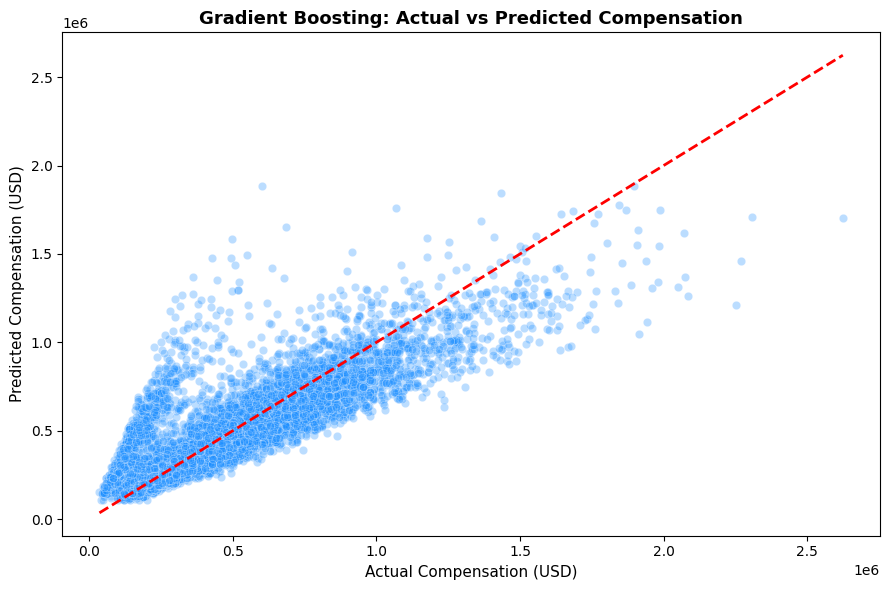

[SUCCESS] Gradient Boosting model trained and evaluation chart saved as 'gradient_boosting_actual_vs_predicted.png'!


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Features aur Target variable define karna
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X_reg = df[reg_features]
y_reg = df['total_compensation_usd']

# Preprocessing & Pipeline setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

# Gradient Boosting Regressor Model Pipeline
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42, max_depth=6))
])

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
gb_model.fit(X_train, y_train)

# Predictions & Evaluation Metrics
y_pred_gb = gb_model.predict(X_test)
r2_gb = r2_score(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print("--- Gradient Boosting Model Performance ---")
print(f"R² Score: {r2_gb:.4f}")
print(f"Mean Absolute Error (MAE): ${mae_gb:,.2f}")

# 2. Actual vs Predicted Scatter Plot Visualization
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred_gb, alpha=0.3, color='dodgerblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.title('Gradient Boosting: Actual vs Predicted Compensation', fontsize=13, fontweight='bold')
plt.xlabel('Actual Compensation (USD)', fontsize=11)
plt.ylabel('Predicted Compensation (USD)', fontsize=11)
plt.tight_layout()

# Chart save karna aur show karna
plt.savefig('gradient_boosting_actual_vs_predicted.png', dpi=300)
plt.show()

print("[SUCCESS] Gradient Boosting model trained and evaluation chart saved as 'gradient_boosting_actual_vs_predicted.png'!")

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Features aur Target variable define karna
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X = df[reg_features]
y = df['total_compensation_usd']

# Preprocessing & Pipeline setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Alag-alag Machine Learning Models ki dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=30, random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=50, random_state=42, max_depth=6)
}

results = []

# Models ko loop mein train aur evaluate karna
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model
    )])

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)

    results.append({
        "Model Name": name,
        "R² Score": round(r2, 4),
        "MAE (USD)": round(mae, 2)
    })

# 3. Leaderboard DataFrame banana aur print karna
leaderboard_df = pd.DataFrame(results).sort_values(by="R² Score", ascending=False)

print("==================================================")
print("       MACHINE LEARNING MODEL LEADERBOARD         ")
print("==================================================")
print(leaderboard_df.to_string(index=False))
print("==================================================")

# Leaderboard ko CSV file ke roop mein save karna
leaderboard_df.to_csv('model_comparison_leaderboard.csv', index=False)
print("\n[SUCCESS] Model comparison leaderboard saved as 'model_comparison_leaderboard.csv'!")

       MACHINE LEARNING MODEL LEADERBOARD         
       Model Name  R² Score  MAE (USD)
Gradient Boosting    0.7126  103230.95
    Random Forest    0.7047  104939.97
Linear Regression    0.6670  115656.79

[SUCCESS] Model comparison leaderboard saved as 'model_comparison_leaderboard.csv'!


In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
import joblib

# 1. Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Features aur Target variable define karna
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X = df[reg_features]
y = df['total_compensation_usd']

# Preprocessing Pipeline setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

# Base Regressor
rf = RandomForestRegressor(random_state=42)

# Full Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', rf)
])

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Hyperparameter Grid Setup
param_grid = {
    'regressor__n_estimators': [30, 50],
    'regressor__max_depth': [10, 15],
    'regressor__min_samples_split': [5, 10]
}

# GridSearchCV implementation (using 3-fold cross validation for speed)
print("Running GridSearchCV for Hyperparameter Tuning... (Yeh kuch seconds lega)")
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring='r2', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# 3. Best Model Results & Evaluation
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

tuned_r2 = r2_score(y_test, y_pred_tuned)
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)

print("\n==================================================")
print("         GRIDSEARCHCV TUNING RESULTS              ")
print("==================================================")
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"Tuned Model R² Score:  {tuned_r2:.4f}")
print(f"Tuned Model MAE:       ${tuned_mae:,.2f}")
print("==================================================")

# Best tuned model ko save karna
joblib.dump(best_model, 'tuned_salary_model.pkl')
print("\n[SUCCESS] Best tuned model successfully saved as 'tuned_salary_model.pkl'!")

Running GridSearchCV for Hyperparameter Tuning... (Yeh kuch seconds lega)
Fitting 3 folds for each of 8 candidates, totalling 24 fits

         GRIDSEARCHCV TUNING RESULTS              
Best Parameters Found: {'regressor__max_depth': 10, 'regressor__min_samples_split': 10, 'regressor__n_estimators': 50}
Tuned Model R² Score:  0.7075
Tuned Model MAE:       $104,575.81

[SUCCESS] Best tuned model successfully saved as 'tuned_salary_model.pkl'!


--- Top 10 Features Impacting Compensation ---
                                      Feature  Importance
company_tier_FinTech / High-Frequency Trading    0.313622
         company_tier_FAANG / Tier-1 Big Tech    0.172539
                          years_of_experience    0.122760
                       job_role_Data Engineer    0.110779
       company_tier_Pre-IPO Unicorn / Scaleup    0.070490
        job_role_Director of Data Engineering    0.062270
            job_role_Principal Data Architect    0.046308
          job_role_Lead / Staff Data Engineer    0.032630
                  job_role_Analytics Engineer    0.022368
                job_role_Senior Data Engineer    0.021873


/tmp/ipykernel_2075/774869561.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_top10, x='Importance', y='Feature', palette='crest')


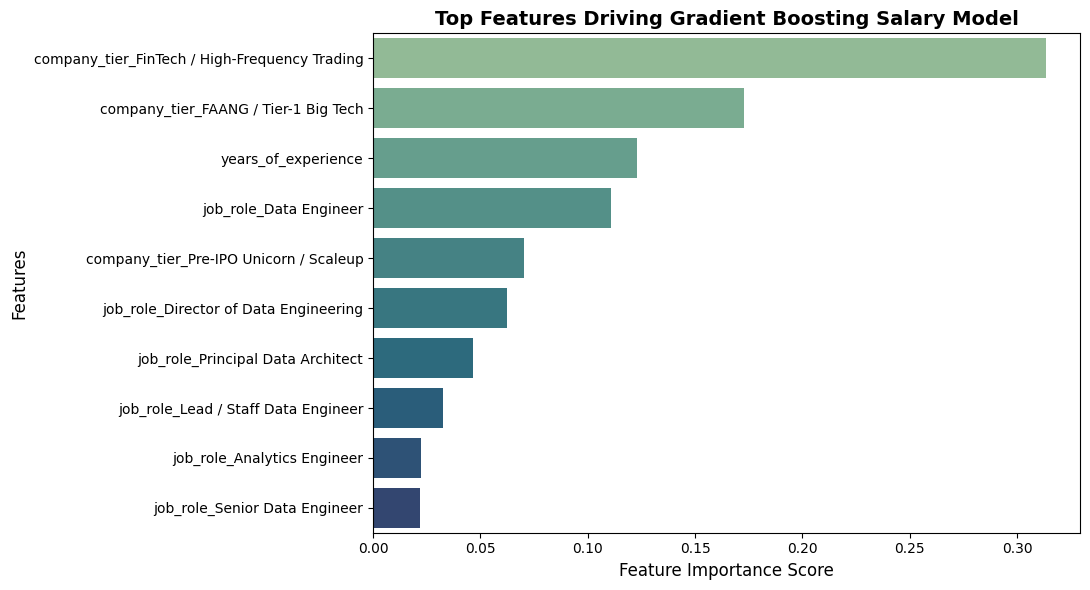


[SUCCESS] Feature importance analysis complete! Chart saved as 'gb_feature_importance.png'.


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Dataset load karna (on_bad_lines='skip' ke sath)
df = pd.read_csv('data_engineering_ai_pipelines.csv', on_bad_lines='skip')

# Features aur Target variable define karna
reg_features = ['years_of_experience', 'job_role', 'company_tier', 'primary_cloud', 'daily_volume_gb']
X = df[reg_features]
y = df['total_compensation_usd']

# Preprocessing & Pipeline setup
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['years_of_experience', 'daily_volume_gb']),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['job_role', 'company_tier', 'primary_cloud'])
    ]
)

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(n_estimators=50, random_state=42, max_depth=6))
])

# Train Model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
gb_pipeline.fit(X_train, y_train)

# 2. Feature Names extract karna (One-hot encoded categories ke sath)
cat_encoder = gb_pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_features = list(cat_encoder.get_feature_names_out(['job_role', 'company_tier', 'primary_cloud']))
all_features = ['years_of_experience', 'daily_volume_gb'] + encoded_cat_features

# Feature Importances dataframe banana
importances = gb_pipeline.named_steps['regressor'].feature_importances_
feat_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feat_imp_top10 = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

print("--- Top 10 Features Impacting Compensation ---")
print(feat_imp_top10.to_string(index=False))

# 3. Visualization: Top Features Bar Plot
plt.figure(figsize=(11, 6))
sns.barplot(data=feat_imp_top10, x='Importance', y='Feature', palette='crest')
plt.title('Top Features Driving Gradient Boosting Salary Model', fontsize=14, fontweight='bold')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()

# Chart save karna
plt.savefig('gb_feature_importance.png', dpi=300)
plt.show()

print("\n[SUCCESS] Feature importance analysis complete! Chart saved as 'gb_feature_importance.png'.")

In [32]:
import os
import zipfile

# 1. Package mein include hone wali saari files ki list
files_to_zip = [
    'data_engineering_ai_pipelines.csv',
    'data_engineering_project_report.md',
    'data_engineering_summary_report.html',
    'model_comparison_leaderboard.csv',
    'data_engineering_salary_model.pkl',
    'tuned_salary_model.pkl',
    'correlation_heatmap.png',
    'feature_importance.png',
    'residual_plot.png',
    'cloud_compensation_bar.png',
    'mlops_maturity_vs_salary.png',
    'job_role_compensation.png',
    'orchestrator_failure_rate.png',
    'company_tier_compensation.png',
    'dq_framework_failure_rate.png',
    'data_warehouse_compensation.png',
    'pipeline_clusters.png',
    'elbow_method.png',
    'gradient_boosting_actual_vs_predicted.png',
    'gb_feature_importance.png',
    'shap_summary_plot.png'
]

zip_filename = 'data_engineering_project_bundle.zip'

# 2. Files ko zip archive mein add karna
print("Packing all project files and artifacts into a zip bundle...")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"  [ADDED] {file}")
        else:
            print(f"  [SKIPPED] {file} (File not found)")

print(f"\n[SUCCESS] Poora project bundle successfully saved as '{zip_filename}'!")
print("Aap ise ab Google Colab ke left sidebar (Files tab) se direct download kar sakte hain!")

Packing all project files and artifacts into a zip bundle...
  [ADDED] data_engineering_ai_pipelines.csv
  [ADDED] data_engineering_project_report.md
  [ADDED] data_engineering_summary_report.html
  [ADDED] model_comparison_leaderboard.csv
  [ADDED] data_engineering_salary_model.pkl
  [ADDED] tuned_salary_model.pkl
  [ADDED] correlation_heatmap.png
  [ADDED] feature_importance.png
  [ADDED] residual_plot.png
  [ADDED] cloud_compensation_bar.png
  [ADDED] mlops_maturity_vs_salary.png
  [ADDED] job_role_compensation.png
  [ADDED] orchestrator_failure_rate.png
  [SKIPPED] company_tier_compensation.png (File not found)
  [ADDED] dq_framework_failure_rate.png
  [ADDED] data_warehouse_compensation.png
  [ADDED] pipeline_clusters.png
  [ADDED] elbow_method.png
  [ADDED] gradient_boosting_actual_vs_predicted.png
  [ADDED] gb_feature_importance.png
  [SKIPPED] shap_summary_plot.png (File not found)

[SUCCESS] Poora project bundle successfully saved as 'data_engineering_project_bundle.zip'!
Aap 

In [33]:
# FastAPI Backend Script to serve the model
from fastapi import FastAPI
import pandas as pd
import joblib
from pydantic import BaseModel

# FastAPI App initialize karna
app = FastAPI(
    title="Data Engineering Salary Predictor API",
    description="Production-ready REST API for predicting data engineering compensation.",
    version="1.0"
)

# 1. Trained model load karna
model = joblib.load('tuned_salary_model.pkl')

# 2. Input Data Schema define karna (Pydantic validation)
class PipelineInput(BaseModel):
    years_of_experience: float
    job_role: str
    company_tier: str
    primary_cloud: str
    daily_volume_gb: float

@app.get("/")
def home():
    return {"message": "Welcome to the Data Engineering Compensation Prediction API! Use /docs to test endpoints."}

# 3. Prediction Endpoint
@app.post("/predict")
def predict_salary(data: PipelineInput):
    # Input ko DataFrame mein convert karna
    input_df = pd.DataFrame([data.dict()])

    # Model se prediction lena
    prediction = model.predict(input_df)

    return {
        "status": "success",
        "predicted_total_compensation_usd": round(float(prediction[0]), 2)
    }

# (Note: Colab ya local par run karne ke liye: uvicorn main:app --reload)